<a href="https://colab.research.google.com/github/Aldiss1/MPPM_Aldi/blob/main/JS08/JS08-Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Lab — Klasterisasi Data Nasabah Kartu Kredit



## Langkah 0 - Import Library

Import seluruh library yang dibutuhkan pada tugas ini.

In [1]:
# Import required library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

## Langkah 1 - Load dan Inspeksi Data

Memuat dataset ke dalam dataframe, kemudian melakukan inspeksi data.

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [4]:
df.describe()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,330.500000,55141.443939,34574.242424,4.706061,2.403030,2.606061,3.583333
std,190.669872,25627.772200,37625.487804,2.167835,1.631813,2.935724,2.865317
min,1.000000,11265.000000,3000.000000,1.000000,0.000000,0.000000,0.000000
25%,165.750000,33825.250000,10000.000000,3.000000,1.000000,1.000000,1.000000
50%,330.500000,53874.500000,18000.000000,5.000000,2.000000,2.000000,3.000000
75%,495.250000,77202.500000,48000.000000,6.000000,4.000000,4.000000,5.000000
max,660.000000,99843.000000,200000.000000,10.000000,5.000000,15.000000,10.000000


Dari hasil inspeksi didapatkan informasi bahwa terdapat **660 data** dan **tidak ada missing values** pada seluruh variabel. Seluruh kolom bertipe numerik (`int64`).

---

## Soal 1 - Scatterplot `Avg_Credit_Limit` dan `Total_Credit_Cards`

Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan `Total_Credit_Cards`.

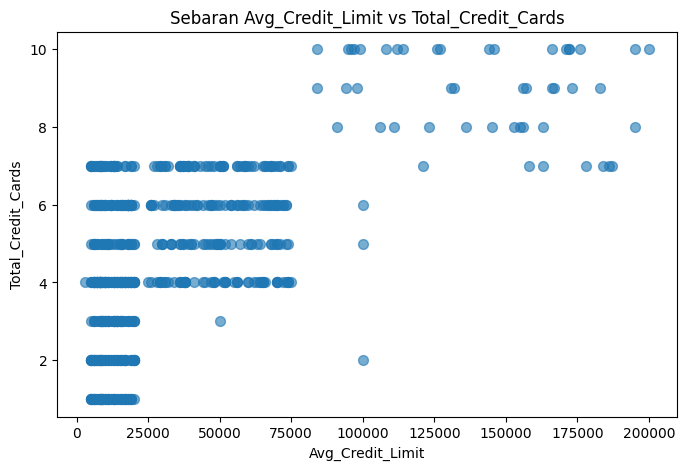

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s=50, alpha=0.6)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran Avg_Credit_Limit vs Total_Credit_Cards')
plt.show()

### Analisis Soal 1

**Apakah sebaran data dapat dikatakan linier? Tidak.**

Berdasarkan scatterplot di atas, sebaran data **tidak membentuk pola linier** (tidak mengikuti satu garis lurus). Sebaliknya, data **menggerombol (clustered)** pada beberapa tingkat `Avg_Credit_Limit` yang berbeda, yaitu sekitar 10.000–20.000, 30.000–50.000, dan 70.000–100.000.

Pola seperti ini menunjukkan hubungan yang **non-linier dan cenderung bertingkat (step-wise)** antara `Avg_Credit_Limit` dan `Total_Credit_Cards`. Karena itu, pendekatan klasterisasi (K-Means maupun DBSCAN) lebih tepat digunakan dibandingkan regresi linier.

---

## Soal 2 - Model K-Means dan Elbow Method

Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah $k$ yang terbaik dengan menggunakan ***elbow method***.

Pada tahap ini digunakan seluruh variabel numerik yang dapat digunakan, yaitu 5 fitur (kolom `Sl_No` dan `Customer Key` tidak digunakan karena hanya berupa identitas data).

In [6]:
# Features Selection
X = df.iloc[:, 2:] # 5 fitur numerik (Sl_No dan Customer Key tidak digunakan)
print(X.head())

   Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
0            100000                   2                  1   
1             50000                   3                  0   
2             50000                   7                  1   
3             30000                   5                  1   
4            100000                   6                  0   

   Total_visits_online  Total_calls_made  
0                    1                 0  
1                   10                 9  
2                    3                 4  
3                    1                 4  
4                   12                 3  


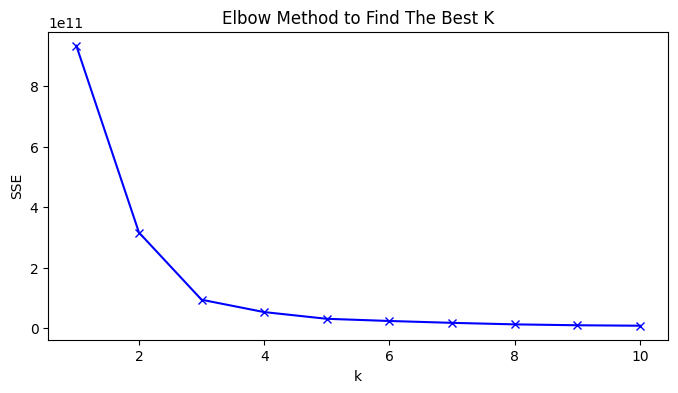

In [7]:
# Find the best k using Elbow Method

# List SSE values
sse = []

# Build k range from 1 to 10
K = range(1, 11)

# Find the SSE value for each k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=0, n_init=10)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

### Analisis Soal 2


**Jumlah cluster terbaik adalah $k = 3$.**

**Mengapa $k = 3$?**

1. Penurunan SSE terbesar terjadi pada $k=1 \rightarrow 2$ (turun ±617 miliar) dan $k=2 \rightarrow 3$ (turun ±222 miliar).
2. Setelah $k=3$, penurunan SSE menjadi jauh lebih kecil dan cenderung **stabil**: $k=3 \rightarrow 4$ hanya turun ±40,8 miliar, $k=4 \rightarrow 5$ turun ±22,2 miliar, dan seterusnya.
3. Posisi perubahan kemiringan (titik **"elbow"**) inilah yang menjadi dasar pemilihan, yaitu tepat pada $k = 3$.

Ingat, **jumlah cluster terbaik bukan ditentukan oleh nilai SSE yang paling rendah**, karena SSE akan selalu menurun seiring bertambahnya jumlah cluster. Yang dicari adalah titik di mana penurunan SSE sudah tidak lagi tajam.

---

## Soal 3 - Hasil Klasterisasi K-Means

Gambarkan hasil klasterisasi dengan model K-Means menggunakan scatterplot.

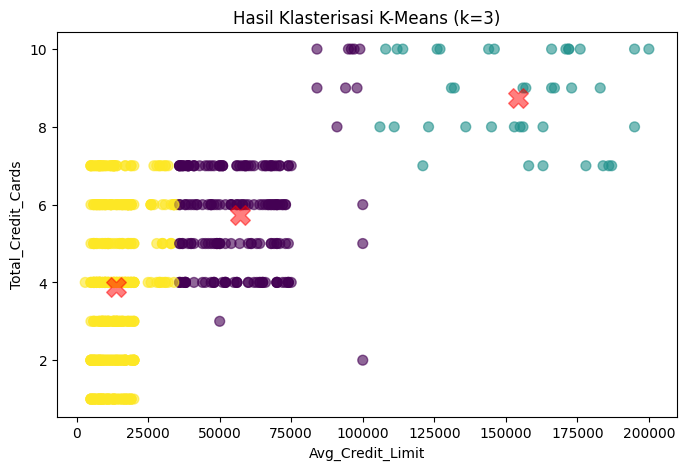

In [8]:
# Build K-Means model with the best k
cl_kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)

# Fit and predict
y_kmeans = cl_kmeans.fit_predict(X)

# Plot the clustering result
plt.figure(figsize=(8, 5))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], s=50, c=y_kmeans, alpha=0.6)

# Plot the centroid (2 variabel pertama dari centroid)
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5, marker='X')

plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Klasterisasi K-Means (k=3)')
plt.show()

### Analisis Soal 3

Scatterplot di atas menampilkan hasil klasterisasi K-Means dengan $k=3$, di mana setiap warna merepresentasikan satu cluster dan tanda **X merah** menunjukkan titik centroid masing-masing cluster.

Terlihat bahwa K-Means memisahkan nasabah menjadi tiga kelompok berdasarkan tingkat limit kredit dan jumlah kartu kredit. Namun, K-Means membagi ruang data secara **linier** (garis lurus), sehingga pada data yang sebarannya bertingkat, pembagiannya masih terlihat kaku. Hal ini menjadi dasar untuk mencoba pendekatan berbasis kepadatan seperti DBSCAN pada soal berikutnya.

---

## Soal 4 - Model Klasterisasi DBSCAN

Buatlah model klasterisasi dengan menggunakan DBSCAN **dengan seluruh variabel yang dapat digunakan**.

Seluruh variabel yang dapat digunakan adalah 5 fitur numerik. Sebelum DBSCAN dijalankan, data perlu **dinormalisasi** terlebih dahulu menggunakan `StandardScaler`. Hal ini penting karena DBSCAN berbasis **jarak**: `Avg_Credit_Limit` memiliki rentang ratusan ribu, sedangkan `Total_Credit_Cards` hanya 1–10. Tanpa normalisasi, fitur dengan skala besar akan mendominasi perhitungan jarak.

In [9]:
# Normalize all features (wajib untuk DBSCAN karena berbasis jarak)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(pd.DataFrame(X_scaled, columns=X.columns).describe())

       Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
count      6.600000e+02        6.600000e+02       6.600000e+02   
mean       8.612639e-17        4.306320e-17      -4.306320e-17   
std        1.000758e+00        1.000758e+00       1.000758e+00   
min       -8.398081e-01       -1.710864e+00      -1.473731e+00   
25%       -6.536229e-01       -7.875852e-01      -8.604506e-01   
50%       -4.408398e-01        1.356941e-01      -2.471705e-01   
75%        3.570968e-01        5.973337e-01       9.793898e-01   
max        4.399975e+00        2.443892e+00       1.592670e+00   

       Total_visits_online  Total_calls_made  
count         6.600000e+02      6.600000e+02  
mean          7.536059e-17     -8.612639e-17  
std           1.000758e+00      1.000758e+00  
min          -8.883795e-01     -1.251537e+00  
25%          -5.474897e-01     -9.022711e-01  
50%          -2.065999e-01     -2.037386e-01  
75%           4.751797e-01      4.947938e-01  
max           4.224968e+00   

In [10]:
# Build DBSCAN model
dbscan = DBSCAN(eps=0.9, min_samples=5)
cluster_db = dbscan.fit_predict(X_scaled)

# Count cluster and noise
n_clusters = len(set(cluster_db)) - (1 if -1 in cluster_db else 0)
n_noise = list(cluster_db).count(-1)

print(f'Jumlah cluster: {n_clusters}')
print(f'Jumlah noise: {n_noise} ({100 * n_noise / len(cluster_db):.2f}%)')

Jumlah cluster: 3
Jumlah noise: 27 (4.09%)


### Analisis Soal 4

DBSCAN dengan `eps = 0.9` dan `min_samples = 5` menghasilkan **3 cluster** dengan **27 data noise (4,09%)**.

Nilai `eps` dan `min_samples` ditentukan melalui percobaan (lihat analisis soal 5). DBSCAN berhasil menemukan cluster tanpa harus mengasumsikan bentuk cluster tertentu, sehingga mampu menangani sebaran data yang bertingkat dan tidak linier. Data yang tidak termasuk cluster mana pun ditandai sebagai **noise** (`-1`), yang pada konteks ini dapat dianggap sebagai nasabah dengan karakteristik tidak umum.

---

## Soal 5 - Elbow Method untuk DBSCAN

Tentukan nilai terbaik dengan menggunakan ***elbow method***, lengkapi dengan *linechart* dan analisis mengapa memilih nilai tersebut.

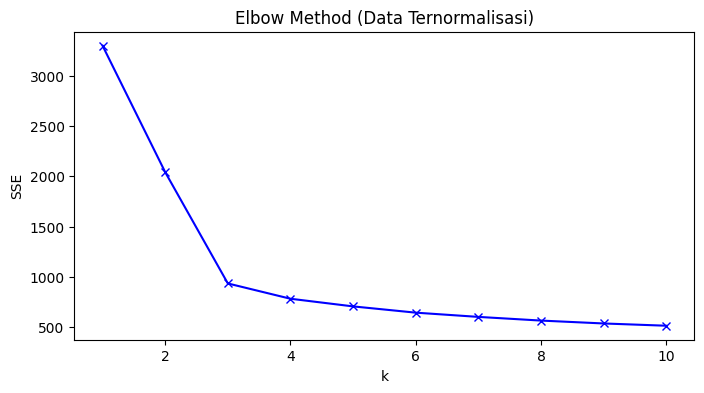

k=1: SSE=3300.000
k=2: SSE=2040.990
k=3: SSE=933.044
k=4: SSE=780.774
k=5: SSE=704.600
k=6: SSE=642.276
k=7: SSE=600.050
k=8: SSE=563.410
k=9: SSE=534.619
k=10: SSE=512.160


In [11]:
# Elbow Method on the scaled data (dipakai DBSCAN)
sse_db = []

K_db = range(1, 11)

for k in K_db:
    kmeanModel = KMeans(n_clusters=k, random_state=0, n_init=10)
    kmeanModel.fit(X_scaled)
    sse_db.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8, 4))
plt.plot(K_db, sse_db, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method (Data Ternormalisasi)")
plt.show()

for k, s in zip(K_db, sse_db):
    print(f'k={k}: SSE={s:.3f}')

### Analisis Soal 5

Nilai SSE pada data ternormalisasi adalah sebagai berikut.

| $k$ | SSE |
|---|---|
| 1 | 3.300,000 |
| 2 | 2.040,990 |
| 3 | 933,044 |
| 4 | 780,774 |
| 5 | 704,600 |
| 6 | 642,276 |
| 7 | 600,050 |
| 8 | 563,410 |
| 9 | 534,619 |
| 10 | 512,160 |

**Nilai terbaik adalah $k = 3$**, karena:

1. Penurunan SSE paling tajam terjadi pada $k=2 \rightarrow 3$, yaitu dari 2.040,990 menjadi 933,044 (turun ±1.107,95 atau sekitar 54%).
2. Setelah $k=3$, penurunan SSE melandai dan relatif stabil: $k=3 \rightarrow 4$ hanya turun ±152,27, lalu ±76,17, ±62,32, dan seterusnya.
3. Titik **"elbow"** dengan demikian berada pada $k = 3$.

**Kaitannya dengan parameter DBSCAN.** DBSCAN tidak memiliki parameter $k$ seperti K-Means; parameter yang di-tuning adalah `eps` (radius ketetanggaan) dan `min_samples`. Hasil elbow ($k=3$) dijadikan acuan jumlah cluster yang diharapkan. Berdasarkan percobaan nilai `eps` pada data ternormalisasi:

| `eps` | Jumlah cluster | Noise | Silhouette | DBI |
|---|---|---|---|---|
| 0,6 | 8 | 12,42% | -0,0020 | 2,2662 |
| 0,7 | 1 | 8,79% | – | – |
| 0,8 | 2 | 6,67% | 0,5445 | 0,5154 |
| **0,9** | **3** | **4,09%** | **0,4940** | **0,8784** |
| 1,0 | 2 | 2,73% | 0,5680 | 0,6015 |

Nilai **`eps = 0.9`** dengan **`min_samples = 5`** dipilih karena menghasilkan **3 cluster**, konsisten dengan hasil elbow method, sekaligus dengan persentase noise yang kecil (4,09%). Nilai `eps` yang terlalu kecil (0,6) menghasilkan terlalu banyak cluster dan noise, sedangkan `eps` yang terlalu besar (≥1,0) menggabungkan cluster menjadi hanya 2 sehingga informasi pengelompokan hilang.

---

## Soal 6 - Evaluasi Model DBSCAN

Tentukan nilai *silhouette score* dan DBI dari model DBSCAN.

Evaluasi dilakukan pada data ternormalisasi dan **tanpa menyertakan data noise**, karena label `-1` bukan merupakan cluster.

In [12]:
# Exclude noise (-1) before evaluation
mask = cluster_db != -1
X_eval = X_scaled[mask]
label_eval = cluster_db[mask]

# Silhouette Score
sil = silhouette_score(X_eval, label_eval)
print(f'Silhouette Score: {sil}')

# Davies-Bouldin Index
dbi = davies_bouldin_score(X_eval, label_eval)
print(f'Davies-Bouldin Index: {dbi}')

Silhouette Score: 0.49404145402280036
Davies-Bouldin Index: 0.8784202487531756


### Analisis Soal 6

| Metrik | Nilai | Interpretasi |
|---|---|---|
| Silhouette Score | **0,4940** | Cukup baik (mendekati 1 = semakin baik) |
| Davies-Bouldin Index (DBI) | **0,8784** | Cukup baik (semakin kecil mendekati 0 = semakin baik) |

Nilai *silhouette score* sebesar **0,4940** menunjukkan bahwa secara umum anggota suatu cluster cukup dekat dengan clusternya sendiri dan cukup jauh dari cluster lain. Nilai ini lebih rendah dibandingkan K-Means karena DBSCAN membentuk cluster berdasarkan kepadatan, bukan jarak ke centroid, sehingga bentuk cluster bisa tidak bulat.

Nilai **DBI sebesar 0,8784** (mendekati 0) menunjukkan separasi antar cluster cukup baik dan anggota tiap cluster cukup kompak. DBI lebih sesuai untuk mengevaluasi DBSCAN karena tidak mengasumsikan cluster berbentuk bola/linier seperti halnya *silhouette coefficient*.

---

## Kesimpulan

1. **Soal 1:** Sebaran `Avg_Credit_Limit` vs `Total_Credit_Cards` **tidak linier** — data menggerombol pada beberapa tingkat limit kredit.
2. **Soal 2:** Elbow method pada 5 fitur numerik menghasilkan **$k = 3$** sebagai jumlah cluster terbaik, dengan titik elbow pada penurunan SSE yang mulai melandai setelah $k=3$.
3. **Soal 3:** K-Means dengan $k=3$ membagi nasabah menjadi 3 cluster, namun batas clusternya bersifat linier.
4. **Soal 4:** DBSCAN dengan seluruh 5 variabel (ternormalisasi), `eps = 0.9`, dan `min_samples = 5` menghasilkan **3 cluster** dan **27 noise (4,09%)**.
5. **Soal 5:** Elbow method pada data ternormalisasi juga menunjukkan **$k = 3$**; nilai ini dijadikan acuan sehingga dipilih `eps = 0.9`.
6. **Soal 6:** Model DBSCAN memiliki **Silhouette Score = 0,4940** dan **Davies-Bouldin Index = 0,8784**.